**Reasoning**:
Install the required packages and import all necessary libraries for data manipulation, visualization, modeling, preprocessing, and evaluation, while setting random seeds for reproducibility.



In [1]:
!pip install -q shap xgboost lightgbm scikit-learn

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import scipy.stats as stats

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, classification_report

# Set random seeds for system-wide reproducibility
random.seed(42)
np.random.seed(42)

print("Libraries successfully imported and seeds set to 42.")

Libraries successfully imported and seeds set to 42.


# Task
Execute a comprehensive machine learning study on Type 2 Diabetes prediction using the dataset "/content/diabetes_master_dataset.csv".

The study must follow a structured pipeline:
1. **Environment Setup & Imports**: Install necessary packages and import standard libraries.
2. **Load and Validate Master Dataset**: Thoroughly inspect "/content/diabetes_master_dataset.csv" for shapes, missing values, duplicates, and target distribution.
3. **Stratified Train-Validation-Test Split**: Implement a 70% train, 15% validation, and 15% test split stratified by the target 'type2_diabetes' (random_state=42).
4. **Common Preprocessing Pipeline**: Build a reproducible pipeline using ColumnTransformer with appropriate imputation, winsorization, ordinal, and one-hot encoding fit on the training data only.
5. **Model Definitions & Hyperparameter Tuning**: Set up five estimators (Logistic Regression, Random Forest, XGBoost, LightGBM, MLP) with grid searches.
6. **Experiment 1 (E1)**: Train and evaluate models using lifestyle, demographic, and clinical features only.
7. **Experiment 2 (E2)**: Train and evaluate models using t2d_prs and family history features only.
8. **Experiment 3 (E3)**: Train and evaluate models combining all raw features from E1 and E2.
9. **Experiment 4 (E4)**: Add non-interaction engineered features to E3.
10. **Experiment 5 (E5)**: Standardize 't2d_prs' and lifestyle variables, and add exactly four interaction terms to model gene-environment interactions.
11. **E6 & Comparisons**: Compare model families, perform statistical bootstrapping comparing E4 vs E5 on the test set, and evaluate calibration.
12. **Explainability & Subgroup Analysis**: Perform SHAP analysis and evaluate performance across subgroups (Sex, Age bands, Genetic risk).
13. **Visualization & Summarization**: Save final evaluation plots, calibration curves, and master result tables to disk.

## Environment Setup & Imports

### Subtask:
Install required packages and import all standard scientific computing and machine learning libraries.


## Load and Validate Master Dataset

### Subtask:
Load, thoroughly inspect, and validate the master diabetes dataset.


**Reasoning**:
Load, thoroughly inspect, and validate the master diabetes dataset, including shape, head, missing values, duplicates, target distribution, and feature types.



In [2]:
df = pd.read_csv('/content/diabetes_master_dataset.csv')
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nTarget variable distribution ('type2_diabetes'):")
print(df['type2_diabetes'].value_counts(dropna=False))
print(df['type2_diabetes'].value_counts(normalize=True) * 100)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nColumn data types:")
print(df.dtypes)

Dataset shape: (7000, 44)

First 5 rows:


,participant_id,age,sex,race_ethnicity,education_level,income_level,t2d_prs,prs_percentile,genetic_risk_category,mother_diabetes,...,waist_circumference,systolic_bp,diastolic_bp,cholesterol,triglycerides,hypertension,diabetes_status,type2_diabetes,age_at_diagnosis,diagnosis_source
0,SYN00001,35,Male,South Asian,Undergraduate,Low,-0.119,45.4,Medium,0,...,86.0,113.0,74.0,164.0,200.0,0,No diabetes,0,NaN,Not applicable
1,SYN00002,49,Female,White,Undergraduate,Middle,-0.480,32.1,Medium,0,...,82.0,102.0,64.0,197.0,79.0,0,No diabetes,0,NaN,Not applicable
2,SYN00003,19,Male,South Asian,Postgraduate,Middle,0.693,75.1,High,1,...,71.0,120.0,72.0,151.0,94.0,0,No diabetes,0,NaN,Not applicable
3,SYN00004,66,Female,East Asian,Secondary,Low,-1.387,8.6,Low,0,...,90.0,130.0,65.0,146.0,148.0,0,No diabetes,0,NaN,Not applicable
4,SYN00005,55,Male,Other,Secondary,NaN,-1.333,9.4,Low,0,...,80.0,114.0,65.0,183.0,245.0,0,No diabetes,0,NaN,Not applicable



Target variable distribution ('type2_diabetes'):
type2_diabetes
0    5983
1    1017
Name: count, dtype: int64
type2_diabetes
0    85.471429
1    14.528571
Name: proportion, dtype: float64

Missing values per column:
participant_id                       0
age                                  0
sex                                  0
race_ethnicity                       0
education_level                    138
income_level                       247
t2d_prs                              0
prs_percentile                       0
genetic_risk_category                0
mother_diabetes                      0
father_diabetes                      0
sibling_diabetes                     0
grandparent_diabetes                 0
family_diabetes_history              0
num_affected_relatives               0
family_history_score                 0
physical_activity_minutes_week     138
moderate_activity_days               0
vigorous_activity_days               0
sedentary_hours_day                170
sle

**Reasoning**:
We need to split the master dataset into train (70%), validation (15%), and test (15%) subsets, ensuring proper stratification by the target variable 'type2_diabetes' and excluding 'participant_id', 'age_at_diagnosis', 'diabetes_status', and 'diagnosis_source' from the features.



In [4]:
# Separate target and features, removing non-predictor columns
columns_to_exclude = ['participant_id', 'age_at_diagnosis', 'diabetes_status', 'diagnosis_source', 'type2_diabetes']
X = df.drop(columns=columns_to_exclude)
y = df['type2_diabetes']

# Split into 70% train and 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

# Split the remaining 30% temp into 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

# Verify and print shapes and distributions
names_mapping = {'Train': 'train', 'Validation': 'val', 'Test': 'test'}
for name, y_subset in zip(['Train', 'Validation', 'Test'], [y_train, y_val, y_test]):
    suffix = names_mapping[name]
    print(f"\n=== {name} Set ===")
    print(f"Shape of X_{suffix}: {globals()[f'X_{suffix}'].shape}")
    print(f"Shape of y_{suffix}: {y_subset.shape}")
    counts = y_subset.value_counts()
    pcts = y_subset.value_counts(normalize=True) * 100
    for val in counts.index:
        print(f"Class {val}: {counts[val]} ({pcts[val]:.2f}%)")


=== Train Set ===
Shape of X_train: (4900, 39)
Shape of y_train: (4900,)
Class 0: 4188 (85.47%)
Class 1: 712 (14.53%)

=== Validation Set ===
Shape of X_val: (1050, 39)
Shape of y_val: (1050,)
Class 0: 897 (85.43%)
Class 1: 153 (14.57%)

=== Test Set ===
Shape of X_test: (1050, 39)
Shape of y_test: (1050,)
Class 0: 898 (85.52%)
Class 1: 152 (14.48%)


### Dataset Validation Summary

- **Shape & Structure**: The master dataset contains **7,000 rows** and **44 columns**.
- **Target Variable (`type2_diabetes`)**:
  - `0` (No Diabetes): **5,983 (85.47%)**
  - `1` (Type 2 Diabetes): **1,017 (14.53%)**
  - This indicates a class imbalance that we must address using stratified splitting and appropriate evaluation metrics (such as ROC-AUC, PR-AUC, etc.).
- **Missing Values**: Missing values are present across several numerical and categorical features (e.g., `education_level`, `income_level`, `bmi`, `cholesterol`, `triglycerides`, etc.). These will be handled during the common preprocessing pipeline. Note that `age_at_diagnosis` has 5,983 missing values, which perfectly corresponds to the non-diabetic participants.
- **Duplicates**: There are **0 duplicate rows** in the dataset.
- **Data Types**: The features consist of categorical (e.g., `sex`, `race_ethnicity`, `education_level`, `income_level`, `smoking_status`, `alcohol_frequency`, `genetic_risk_category`, `diabetes_status`, `diagnosis_source`), numerical variables (both integer and float), and an identifier column (`participant_id`).

## Stratified Train-Validation-Test Split

### Subtask:
Split the master dataset into stratified train, validation, and test subsets.


## Common Preprocessing Pipeline Setup

### Subtask:
Create a robust, reproducible sklearn preprocessing pipeline using ColumnTransformer to handle imputation, scaling, outlier handling, and categorical encoding on the training set.


**Reasoning**:
We will define and test a robust preprocessing pipeline using ColumnTransformer to group numerical, ordinal, and nominal variables, handle outliers using clipping (winsorization), impute missing values, and encode categorical features.



In [11]:
from sklearn.base import BaseEstimator, TransformerMixin, OneToOneFeatureMixin

# 1. Group features
# Identify numerical columns
num_cols = [
    'age', 't2d_prs', 'prs_percentile', 'physical_activity_minutes_week',
    'moderate_activity_days', 'vigorous_activity_days', 'sedentary_hours_day',
    'sleep_duration_hours', 'sleep_quality_score', 'fruit_intake', 'vegetable_intake',
    'whole_grain_intake', 'processed_food_frequency', 'sugary_drink_frequency',
    'diet_quality_score', 'smoking_pack_years', 'stress_level', 'bmi',
    'waist_circumference', 'systolic_bp', 'diastolic_bp', 'cholesterol', 'triglycerides'
]

# Binary and family history columns
family_cols = [
    'mother_diabetes', 'father_diabetes', 'sibling_diabetes', 'grandparent_diabetes',
    'family_diabetes_history', 'num_affected_relatives', 'family_history_score',
    'alcohol_use', 'hypertension'
]
all_num_cols = num_cols + family_cols

# Ordinal columns with natural hierarchy
ordinal_cols = ['education_level', 'income_level', 'alcohol_frequency']

# Nominal columns (one-hot encoding)
nominal_cols = ['sex', 'race_ethnicity', 'genetic_risk_category', 'smoking_status']

# Orders for OrdinalEncoder
edu_order = ['Primary or below', 'Secondary', 'Undergraduate', 'Postgraduate']
inc_order = ['Low', 'Middle', 'High']
alc_order = ['None', 'Rare', 'Social', 'Frequent']

# 2. Define custom Winsorization Transformer with OneToOneFeatureMixin and set_output support
class OutlierWinsorizer(OneToOneFeatureMixin, BaseEstimator, TransformerMixin):
    def __init__(self, lower_quantile=0.005, upper_quantile=0.995):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile
        self.lower_bounds_ = {}
        self.upper_bounds_ = {}
        self._transform_output = None

    def fit(self, X, y=None):
        if hasattr(X, 'columns'):
            cols = X.columns
            self.feature_names_in_ = np.array(cols, dtype=object)
        else:
            cols = range(X.shape[1])
            self.feature_names_in_ = np.array([f'x{i}' for i in cols], dtype=object)

        X_df = pd.DataFrame(X, columns=cols)
        for col in cols:
            self.lower_bounds_[col] = X_df[col].quantile(self.lower_quantile)
            self.upper_bounds_[col] = X_df[col].quantile(self.upper_quantile)
        return self

    def transform(self, X):
        if hasattr(X, 'columns'):
            cols = X.columns
        else:
            cols = list(self.lower_bounds_.keys())

        X_df = pd.DataFrame(X, columns=cols).copy()
        for col in cols:
            if col in self.lower_bounds_:
                X_df[col] = X_df[col].clip(lower=self.lower_bounds_[col], upper=self.upper_bounds_[col])

        if self._transform_output == 'pandas' or (hasattr(self, '_get_output_config') and self._get_output_config().get('transform') == 'pandas'):
            return X_df
        return X_df.to_numpy()

    def set_output(self, transform=None):
        self._transform_output = transform
        return self

# 3. Numerical Pipeline
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('winsorizer', OutlierWinsorizer(lower_quantile=0.005, upper_quantile=0.995)),
    ('scaler', StandardScaler())
])

# 4. Ordinal Pipeline
ord_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[edu_order, inc_order, alc_order], handle_unknown='use_encoded_value', unknown_value=-1))
])

# 5. Nominal Pipeline
nom_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 6. Combined ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, all_num_cols),
    ('ord', ord_pipeline, ordinal_cols),
    ('nom', nom_pipeline, nominal_cols)
])

# 7. Test fit on X_train
preprocessor.fit(X_train)
print("Common preprocessing pipeline successfully defined and fitted on X_train.")

Common preprocessing pipeline successfully defined and fitted on X_train.


**Reasoning**:
We will configure scikit-learn to output pandas DataFrames and apply this setting to the preprocessing pipeline, resolving the feature name mismatch warning for estimators like LightGBM.



In [10]:
import sklearn

# Configure scikit-learn globally to output pandas DataFrames
sklearn.set_config(transform_output="pandas")

# Re-configure the preprocessors to ensure they output pandas DataFrames
preprocessor.set_output(transform="pandas")
preprocessor_e1.set_output(transform="pandas")

# Verify feature output format
X_train_e1_trans = preprocessor_e1.transform(X_train_e1)
print("Transformed features sample (first 2 rows):")
display(X_train_e1_trans.head(2))
print("Column names of transformed data:", list(X_train_e1_trans.columns[:5]))
print("Preprocessing pipeline configured to output pandas DataFrames successfully.")

ValueError: Unable to configure output for OutlierWinsorizer() because `set_output` is not available.

## Model Definitions & Hyperparameter Tuning Setup

### Subtask:
Define 5 core machine learning estimators (Logistic Regression, Random Forest, XGBoost, LightGBM, MLP) and set up their corresponding hyperparameter search grids.


**Reasoning**:
Import the necessary estimators and define the hyperparameter search spaces along with a unified modeling pipeline dictionary for Experiment 1 through Experiment 5.



In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.neural_network import MLPClassifier

# 1. Define base estimators
estimators = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=42, verbosity=-1),
    'MLP': MLPClassifier(random_state=42, max_iter=500)
}

# 2. Define hyperparameter search spaces
param_grids = {
    'Logistic Regression': {
        'classifier__C': [0.01, 0.1, 1.0, 10.0],
        'classifier__penalty': ['l2']
    },
    'Random Forest': {
        'classifier__n_estimators': [100, 200],
        'classifier__max_depth': [5, 10, None],
        'classifier__min_samples_split': [2, 5]
    },
    'XGBoost': {
        'classifier__n_estimators': [100, 200],
        'classifier__max_depth': [3, 6],
        'classifier__learning_rate': [0.01, 0.1]
    },
    'LightGBM': {
        'classifier__n_estimators': [100, 200],
        'classifier__max_depth': [3, 6, -1],
        'classifier__learning_rate': [0.01, 0.1]
    },
    'MLP': {
        'classifier__hidden_layer_sizes': [(64, 32), (128,)],
        'classifier__alpha': [0.0001, 0.001],
        'classifier__learning_rate_init': [0.001, 0.01]
    }
}

# Note: Advanced deep tabular architectures (like TabNet, SAINT, or TabPFN) are computationally expensive
# and offer limited out-of-the-box performance gains over well-tuned GBDTs within Colab's standard hardware limits,
# hence we stick to MLP as our neural baseline.

print("Estimators and hyperparameter grids successfully initialized.")

Estimators and hyperparameter grids successfully initialized.


## E1: Baseline Lifestyle, Demographic & Clinical Model

### Subtask:
Train and evaluate models using lifestyle, demographic, and clinical features only (excluding all genetic and family history variables).


**Reasoning**:
Train and evaluate five machine learning models (Logistic Regression, Random Forest, XGBoost, LightGBM, MLP) using only lifestyle, demographic, and clinical features (Experiment E1) by filtering features, adapting the preprocessing pipeline, performing GridSearchCV optimized for ROC-AUC, and logging validation/test performance.



In [7]:
from sklearn.metrics import precision_recall_curve

# 1. Define columns to exclude for E1 (Genetic and Family History features)
e1_exclude_cols = [
    't2d_prs', 'prs_percentile', 'genetic_risk_category',
    'mother_diabetes', 'father_diabetes', 'sibling_diabetes', 'grandparent_diabetes',
    'family_diabetes_history', 'num_affected_relatives', 'family_history_score'
]

# Filter features
X_train_e1 = X_train.drop(columns=e1_exclude_cols)
X_val_e1 = X_val.drop(columns=e1_exclude_cols)
X_test_e1 = X_test.drop(columns=e1_exclude_cols)

# 2. Adapt the preprocessor for E1 columns
num_cols_e1 = [c for c in all_num_cols if c not in e1_exclude_cols]
ordinal_cols_e1 = [c for c in ordinal_cols if c not in e1_exclude_cols]
nominal_cols_e1 = [c for c in nominal_cols if c not in e1_exclude_cols]

preprocessor_e1 = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols_e1),
    ('ord', ord_pipeline, ordinal_cols_e1),
    ('nom', nom_pipeline, nominal_cols_e1)
])

# 3. Grid Search loop
e1_results = {}
best_estimators_e1 = {}

for name, model in estimators.items():
    print(f"Training {name} for E1...")
    # Build pipeline
    pipeline = Pipeline([
        ('preprocessor', preprocessor_e1),
        ('classifier', model)
    ])

    # Setup GridSearchCV
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring='roc_auc',
        cv=5,
        n_jobs=-1,
        verbose=0
    )

    # Fit grid search
    grid_search.fit(X_train_e1, y_train)
    best_model = grid_search.best_estimator_
    best_estimators_e1[name] = best_model

    # Predict probabilities on Validation
    val_probs = best_model.predict_proba(X_val_e1)[:, 1]
    val_auc = roc_auc_score(y_val, val_probs)
    val_ap = average_precision_score(y_val, val_probs)
    val_brier = brier_score_loss(y_val, val_probs)

    # Find best threshold on validation set maximizing F1-score
    precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

    # Predict probabilities and classes on Test using best threshold
    test_probs = best_model.predict_proba(X_test_e1)[:, 1]
    test_preds = (test_probs >= best_threshold).astype(int)

    test_auc = roc_auc_score(y_test, test_probs)
    test_ap = average_precision_score(y_test, test_probs)
    test_brier = brier_score_loss(y_test, test_probs)

    # Save metrics
    e1_results[name] = {
        'Best Params': grid_search.best_params_,
        'Val ROC-AUC': val_auc,
        'Val PR-AUC': val_ap,
        'Val Brier': val_brier,
        'Best Threshold': best_threshold,
        'Test ROC-AUC': test_auc,
        'Test PR-AUC': test_ap,
        'Test Brier': test_brier
    }

    print(f"{name} E1 - Val AUC: {val_auc:.4f} | Test AUC: {test_auc:.4f} (Threshold: {best_threshold:.4f})")

# Convert results to DataFrame for nice visualization
df_e1_results = pd.DataFrame(e1_results).T
display(df_e1_results)

Training Logistic Regression for E1...
Logistic Regression E1 - Val AUC: 0.7885 | Test AUC: 0.7448 (Threshold: 0.2093)
Training Random Forest for E1...
Random Forest E1 - Val AUC: 0.7776 | Test AUC: 0.7306 (Threshold: 0.1654)
Training XGBoost for E1...
XGBoost E1 - Val AUC: 0.7821 | Test AUC: 0.7452 (Threshold: 0.1793)
Training LightGBM for E1...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM E1 - Val AUC: 0.7836 | Test AUC: 0.7442 (Threshold: 0.1808)
Training MLP for E1...
MLP E1 - Val AUC: 0.6865 | Test AUC: 0.6448 (Threshold: 0.0016)


,Best Params,Val ROC-AUC,Val PR-AUC,Val Brier,Best Threshold,Test ROC-AUC,Test PR-AUC,Test Brier
Logistic Regression,"{'classifier__C': 0.1, 'classifier__penalty': ...",0.788489,0.406068,0.105302,0.2093,0.744842,0.389666,0.109108
Random Forest,"{'classifier__max_depth': 5, 'classifier__min_...",0.777559,0.39591,0.108303,0.165369,0.730586,0.351158,0.111828
XGBoost,"{'classifier__learning_rate': 0.01, 'classifie...",0.782102,0.398547,0.107299,0.179284,0.745172,0.368143,0.11008
LightGBM,"{'classifier__learning_rate': 0.01, 'classifie...",0.783589,0.39725,0.107123,0.180809,0.744157,0.362788,0.110399
MLP,"{'classifier__alpha': 0.001, 'classifier__hidd...",0.686493,0.275927,0.17648,0.001573,0.644803,0.22605,0.191296


**Reasoning**:
We will configure the scikit-learn preprocessing pipelines to output pandas DataFrames using `set_output(transform='pandas')`. This ensures that all downstream estimators (especially LightGBM) receive feature names, eliminating the feature names mismatch warning.



In [35]:
# Configure scikit-learn globally to output pandas DataFrames from transformers
import sklearn
sklearn.set_config(transform_output="pandas")

# Redefine preprocessor_e1 using the compliant OutlierWinsorizer to support set_output("pandas")
preprocessor_e1_fixed = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols_e1),
    ('ord', ord_pipeline, ordinal_cols_e1),
    ('nom', nom_pipeline, nominal_cols_e1)
])

preprocessor_e1_fixed.set_output(transform="pandas")
preprocessor_e1_fixed.fit(X_train_e1)

# Test transform to verify feature names are present without any warnings or errors
X_train_e1_trans = preprocessor_e1_fixed.transform(X_train_e1)
print("Transformed features sample (first 2 rows):")
display(X_train_e1_trans.head(2))
print("Column names of transformed data:", list(X_train_e1_trans.columns[:5]))
print("Preprocessing pipeline configured to output pandas DataFrames successfully!")

Transformed features sample (first 2 rows):


,num__age,num__physical_activity_minutes_week,num__moderate_activity_days,num__vigorous_activity_days,num__sedentary_hours_day,num__sleep_duration_hours,num__sleep_quality_score,num__fruit_intake,num__vegetable_intake,num__whole_grain_intake,...,nom__sex_Male,nom__race_ethnicity_Black,nom__race_ethnicity_East Asian,nom__race_ethnicity_Hispanic,nom__race_ethnicity_Other,nom__race_ethnicity_South Asian,nom__race_ethnicity_White,nom__smoking_status_Current,nom__smoking_status_Former,nom__smoking_status_Never
3885,-2.036664,0.821679,2.065396,0.743017,-2.648206,-0.750721,0.027007,-1.089019,-0.458961,-0.349489,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
6445,-0.795586,-1.503260,-1.539819,-1.098552,-0.302017,-0.110122,0.027007,0.875887,-0.075384,-0.349489,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


Column names of transformed data: ['num__age', 'num__physical_activity_minutes_week', 'num__moderate_activity_days', 'num__vigorous_activity_days', 'num__sedentary_hours_day']
Preprocessing pipeline configured to output pandas DataFrames successfully!


# Task
Execute **Experiment 2 (E2)** to train and evaluate models using only `t2d_prs` and family history predictors (excluding lifestyle/clinical features) on the dataset "/content/diabetes_master_dataset.csv".

In doing so, make sure to address the LightGBM feature names warning observed in E1. This warning occurs when scikit-learn's `ColumnTransformer` transforms input pandas DataFrames into raw numpy arrays (which lack feature names), causing estimators like LightGBM to emit a warning when fitted on named features but validated or tested on unnamed numpy arrays. Fix the pipeline to ensure consistent type and feature name passing (e.g., by ensuring the preprocessed output is consistently wrapped back into a pandas DataFrame with feature names, or by ensuring LightGBM receives consistent inputs without mismatched feature names).

For E2:
1. Filter the datasets to include only `t2d_prs` and family history features (including `prs_percentile`, `genetic_risk_category`, `mother_diabetes`, `father_diabetes`, `sibling_diabetes`, `grandparent_diabetes`, `family_diabetes_history`, `num_affected_relatives`, `family_history_score`).
2. Adapt the preprocessing pipeline specifically for this subset.
3. Train and hyperparameter tune all 5 models (Logistic Regression, Random Forest, XGBoost, LightGBM, MLP) using the adapted preprocessor and grid searches with 5-fold cross-validation optimized for ROC-AUC.
4. Select decision thresholds on validation data (maximizing the validation F1-score), evaluate on validation and test data, and log all performance metrics (ROC-AUC, PR-AUC, Brier score, and best threshold) to a results dictionary.

## Debug LightGBM Feature Names Warning

### Subtask:
Resolve the LightGBM feature name warning by ensuring consistent feature name handling through the scikit-learn pipeline.


In [12]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.metrics import precision_recall_curve, roc_auc_score, average_precision_score, brier_score_loss
from sklearn.model_selection import GridSearchCV

# Configure scikit-learn globally to output pandas DataFrames
sklearn.set_config(transform_output="pandas")

# Redefine a robust custom OutlierWinsorizer that natively handles and outputs Pandas DataFrames
class OutlierWinsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lower_quantile=0.005, upper_quantile=0.995):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile
        self.lower_bounds_ = {}
        self.upper_bounds_ = {}
        self.columns_ = None

    def fit(self, X, y=None):
        if isinstance(X, pd.DataFrame):
            self.columns_ = X.columns.tolist()
            X_df = X
        else:
            X_df = pd.DataFrame(X)
            self.columns_ = X_df.columns.tolist()

        for col in self.columns_:
            self.lower_bounds_[col] = X_df[col].quantile(self.lower_quantile)
            self.upper_bounds_[col] = X_df[col].quantile(self.upper_quantile)
        return self

    def transform(self, X):
        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(X, columns=self.columns_).copy()

        for col in self.columns_:
            if col in self.lower_bounds_:
                X_df[col] = X_df[col].clip(lower=self.lower_bounds_[col], upper=self.upper_bounds_[col])
        return X_df

    def get_feature_names_out(self, input_features=None):
        if input_features is not None:
            return np.array(input_features, dtype=object)
        return np.array(self.columns_, dtype=object)

# 1. Select only genetic and family history columns for E2
e2_cols = [
    't2d_prs', 'prs_percentile', 'genetic_risk_category', 'mother_diabetes',
    'father_diabetes', 'sibling_diabetes', 'grandparent_diabetes',
    'family_diabetes_history', 'num_affected_relatives', 'family_history_score'
]

X_train_e2 = X_train[e2_cols]
X_val_e2 = X_val[e2_cols]
X_test_e2 = X_test[e2_cols]

# Separate into column types for ColumnTransformer
num_cols_e2 = ['t2d_prs', 'prs_percentile', 'mother_diabetes', 'father_diabetes',
               'sibling_diabetes', 'grandparent_diabetes', 'family_diabetes_history',
               'num_affected_relatives', 'family_history_score']
nominal_cols_e2 = ['genetic_risk_category']

# 2. Re-create sub-pipelines ensuring set_output("pandas") compatibility
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('winsorizer', OutlierWinsorizer(lower_quantile=0.005, upper_quantile=0.995)),
    ('scaler', StandardScaler())
])

nom_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine into E2 ColumnTransformer
preprocessor_e2 = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols_e2),
    ('nom', nom_pipeline, nominal_cols_e2)
])

preprocessor_e2.set_output(transform="pandas")
preprocessor_e2.fit(X_train_e2)

print("E2 Preprocessor successfully defined, set to output pandas DataFrames, and fitted on E2 columns.")

E2 Preprocessor successfully defined, set to output pandas DataFrames, and fitted on E2 columns.


In [13]:
# 3. Execute Experiment 2 Grid Search & Evaluation
e2_results = {}
best_estimators_e2 = {}

for name, model in estimators.items():
    print(f"Training {name} for E2...")

    # Construct full pipeline
    pipeline = Pipeline([
        ('preprocessor', preprocessor_e2),
        ('classifier', model)
    ])

    # Setup Grid Search
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring='roc_auc',
        cv=5,
        n_jobs=-1,
        verbose=0
    )

    # Fit
    grid_search.fit(X_train_e2, y_train)
    best_model = grid_search.best_estimator_
    best_estimators_e2[name] = best_model

    # Validation metrics
    val_probs = best_model.predict_proba(X_val_e2)[:, 1]
    val_auc = roc_auc_score(y_val, val_probs)
    val_ap = average_precision_score(y_val, val_probs)
    val_brier = brier_score_loss(y_val, val_probs)

    # Threshold Optimization (maximizing F1-score on validation set)
    precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

    # Test metrics with best threshold
    test_probs = best_model.predict_proba(X_test_e2)[:, 1]
    test_preds = (test_probs >= best_threshold).astype(int)
    test_auc = roc_auc_score(y_test, test_probs)
    test_ap = average_precision_score(y_test, test_probs)
    test_brier = brier_score_loss(y_test, test_probs)

    e2_results[name] = {
        'Best Params': grid_search.best_params_,
        'Val ROC-AUC': val_auc,
        'Val PR-AUC': val_ap,
        'Val Brier': val_brier,
        'Best Threshold': best_threshold,
        'Test ROC-AUC': test_auc,
        'Test PR-AUC': test_ap,
        'Test Brier': test_brier
    }

    print(f"{name} E2 - Val AUC: {val_auc:.4f} | Test AUC: {test_auc:.4f} (Threshold: {best_threshold:.4f})")

df_e2_results = pd.DataFrame(e2_results).T
display(df_e2_results)

Training Logistic Regression for E2...
Logistic Regression E2 - Val AUC: 0.6850 | Test AUC: 0.6562 (Threshold: 0.1643)
Training Random Forest for E2...
Random Forest E2 - Val AUC: 0.6885 | Test AUC: 0.6543 (Threshold: 0.1626)
Training XGBoost for E2...
XGBoost E2 - Val AUC: 0.6822 | Test AUC: 0.6561 (Threshold: 0.1709)
Training LightGBM for E2...
LightGBM E2 - Val AUC: 0.6847 | Test AUC: 0.6532 (Threshold: 0.1780)
Training MLP for E2...
MLP E2 - Val AUC: 0.6818 | Test AUC: 0.6394 (Threshold: 0.1446)


,Best Params,Val ROC-AUC,Val PR-AUC,Val Brier,Best Threshold,Test ROC-AUC,Test PR-AUC,Test Brier
Logistic Regression,"{'classifier__C': 1.0, 'classifier__penalty': ...",0.684978,0.264165,0.1179,0.164258,0.656195,0.28066,0.117664
Random Forest,"{'classifier__max_depth': 5, 'classifier__min_...",0.688544,0.271315,0.117392,0.162574,0.654334,0.275023,0.117388
XGBoost,"{'classifier__learning_rate': 0.01, 'classifie...",0.682227,0.263333,0.117842,0.170896,0.656067,0.269012,0.117965
LightGBM,"{'classifier__learning_rate': 0.01, 'classifie...",0.684722,0.264481,0.117798,0.177999,0.653195,0.270799,0.117788
MLP,"{'classifier__alpha': 0.0001, 'classifier__hid...",0.681786,0.266305,0.118561,0.144551,0.639396,0.259115,0.118902


# Experiment 3 (E3): Combined Raw Feature Set Model

In this experiment, we combine the features from **E1** (Lifestyle, Demographic, and Clinical) and **E2** (Genetic and Family History) into a single baseline raw feature space to assess the predictive capability of the model when both modalities are present.

In [14]:
# 1. Combine all features from E1 and E2
e3_cols = list(X_train.columns) # X_train already contains all 39 baseline predictor variables

X_train_e3 = X_train[e3_cols]
X_val_e3 = X_val[e3_cols]
X_test_e3 = X_test[e3_cols]

# 2. Build the adapted E3 ColumnTransformer utilizing our robust OutlierWinsorizer
# The common preprocessing pipeline defined in cell 9ffa165f handles all these features correctly,
# but we re-instantiate it here ensuring full compatibility with pandas DataFrame output.
preprocessor_e3 = ColumnTransformer(transformers=[
    ('num', num_pipeline, all_num_cols),
    ('ord', ord_pipeline, ordinal_cols),
    ('nom', nom_pipeline, nominal_cols)
])

preprocessor_e3.set_output(transform="pandas")
preprocessor_e3.fit(X_train_e3)

print("E3 Preprocessor successfully defined and fitted on all raw baseline columns.")

E3 Preprocessor successfully defined and fitted on all raw baseline columns.


In [15]:
# 3. Execute Experiment 3 Grid Search & Evaluation
e3_results = {}
best_estimators_e3 = {}

for name, model in estimators.items():
    print(f"Training {name} for E3...")

    # Construct full pipeline
    pipeline = Pipeline([
        ('preprocessor', preprocessor_e3),
        ('classifier', model)
    ])

    # Setup Grid Search
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring='roc_auc',
        cv=5,
        n_jobs=-1,
        verbose=0
    )

    # Fit
    grid_search.fit(X_train_e3, y_train)
    best_model = grid_search.best_estimator_
    best_estimators_e3[name] = best_model

    # Validation metrics
    val_probs = best_model.predict_proba(X_val_e3)[:, 1]
    val_auc = roc_auc_score(y_val, val_probs)
    val_ap = average_precision_score(y_val, val_probs)
    val_brier = brier_score_loss(y_val, val_probs)

    # Threshold Optimization (maximizing F1-score on validation set)
    precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

    # Test metrics with best threshold
    test_probs = best_model.predict_proba(X_test_e3)[:, 1]
    test_preds = (test_probs >= best_threshold).astype(int)
    test_auc = roc_auc_score(y_test, test_probs)
    test_ap = average_precision_score(y_test, test_probs)
    test_brier = brier_score_loss(y_test, test_probs)

    e3_results[name] = {
        'Best Params': grid_search.best_params_,
        'Val ROC-AUC': val_auc,
        'Val PR-AUC': val_ap,
        'Val Brier': val_brier,
        'Best Threshold': best_threshold,
        'Test ROC-AUC': test_auc,
        'Test PR-AUC': test_ap,
        'Test Brier': test_brier
    }

    print(f"{name} E3 - Val AUC: {val_auc:.4f} | Test AUC: {test_auc:.4f} (Threshold: {best_threshold:.4f})")

df_e3_results = pd.DataFrame(e3_results).T
display(df_e3_results)

Training Logistic Regression for E3...
Logistic Regression E3 - Val AUC: 0.8221 | Test AUC: 0.7791 (Threshold: 0.2877)
Training Random Forest for E3...
Random Forest E3 - Val AUC: 0.8058 | Test AUC: 0.7689 (Threshold: 0.2250)
Training XGBoost for E3...
XGBoost E3 - Val AUC: 0.8078 | Test AUC: 0.7760 (Threshold: 0.2074)
Training LightGBM for E3...
LightGBM E3 - Val AUC: 0.8044 | Test AUC: 0.7712 (Threshold: 0.2154)
Training MLP for E3...
MLP E3 - Val AUC: 0.6901 | Test AUC: 0.6574 (Threshold: 0.0103)


,Best Params,Val ROC-AUC,Val PR-AUC,Val Brier,Best Threshold,Test ROC-AUC,Test PR-AUC,Test Brier
Logistic Regression,"{'classifier__C': 0.1, 'classifier__penalty': ...",0.82213,0.469205,0.099107,0.287723,0.779136,0.407069,0.105923
Random Forest,"{'classifier__max_depth': 5, 'classifier__min_...",0.805765,0.448263,0.103729,0.225015,0.768946,0.374953,0.108124
XGBoost,"{'classifier__learning_rate': 0.1, 'classifier...",0.807776,0.457272,0.100949,0.207408,0.776023,0.379462,0.108135
LightGBM,"{'classifier__learning_rate': 0.1, 'classifier...",0.804359,0.450285,0.101819,0.215413,0.771239,0.375453,0.109125
MLP,"{'classifier__alpha': 0.001, 'classifier__hidd...",0.690063,0.288579,0.156905,0.010276,0.657441,0.26934,0.169345


# Experiment 4 (E4): Non-Interaction Feature Engineering

In this experiment, we enrich our combined dataset (E3) with complex non-interaction engineered features capturing specific cardiovascular, activity, lifestyle, and obesity-age domains. We will engineer:
1. **Cardiovascular Risk Index (CVRI):** `systolic_bp` * `diastolic_bp` / 100
2. **Sleep-to-Sedentary Ratio (SSR):** `sleep_duration_hours` / (`sedentary_hours_day` + 0.1)
3. **Diet-Activity Synergy (DAS):** `diet_quality_score` * `physical_activity_minutes_week`
4. **Obesity-Age Score (OAS):** `bmi` * `age`

In [16]:
# 1. Define feature engineering function
def engineer_e4_features(df_in):
    df_out = df_in.copy()
    df_out['cardiovascular_risk_index'] = df_out['systolic_bp'] * df_out['diastolic_bp'] / 100.0
    df_out['sleep_to_sedentary_ratio'] = df_out['sleep_duration_hours'] / (df_out['sedentary_hours_day'] + 0.1)
    df_out['diet_activity_synergy'] = df_out['diet_quality_score'] * df_out['physical_activity_minutes_week']
    df_out['obesity_age_score'] = df_out['bmi'] * df_out['age']
    return df_out

# 2. Engineer features for Train, Validation, and Test sets
X_train_e4 = engineer_e4_features(X_train)
X_val_e4 = engineer_e4_features(X_val)
X_test_e4 = engineer_e4_features(X_test)

# Update numerical column groups to include newly created numeric engineered features
new_engineered_cols = ['cardiovascular_risk_index', 'sleep_to_sedentary_ratio', 'diet_activity_synergy', 'obesity_age_score']
all_num_cols_e4 = all_num_cols + new_engineered_cols

# 3. Re-define the preprocessing pipeline to handle the new features
preprocessor_e4 = ColumnTransformer(transformers=[
    ('num', num_pipeline, all_num_cols_e4),
    ('ord', ord_pipeline, ordinal_cols),
    ('nom', nom_pipeline, nominal_cols)
])

preprocessor_e4.set_output(transform="pandas")
preprocessor_e4.fit(X_train_e4)

print("E4 Preprocessor successfully defined and fitted with engineered features:", new_engineered_cols)

E4 Preprocessor successfully defined and fitted with engineered features: ['cardiovascular_risk_index', 'sleep_to_sedentary_ratio', 'diet_activity_synergy', 'obesity_age_score']


In [17]:
# 4. Execute Experiment 4 Grid Search & Evaluation
e4_results = {}
best_estimators_e4 = {}

for name, model in estimators.items():
    print(f"Training {name} for E4...")

    # Construct full pipeline
    pipeline = Pipeline([
        ('preprocessor', preprocessor_e4),
        ('classifier', model)
    ])

    # Setup Grid Search
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring='roc_auc',
        cv=5,
        n_jobs=-1,
        verbose=0
    )

    # Fit
    grid_search.fit(X_train_e4, y_train)
    best_model = grid_search.best_estimator_
    best_estimators_e4[name] = best_model

    # Validation metrics
    val_probs = best_model.predict_proba(X_val_e4)[:, 1]
    val_auc = roc_auc_score(y_val, val_probs)
    val_ap = average_precision_score(y_val, val_probs)
    val_brier = brier_score_loss(y_val, val_probs)

    # Threshold Optimization (maximizing F1-score on validation set)
    precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

    # Test metrics with best threshold
    test_probs = best_model.predict_proba(X_test_e4)[:, 1]
    test_preds = (test_probs >= best_threshold).astype(int)
    test_auc = roc_auc_score(y_test, test_probs)
    test_ap = average_precision_score(y_test, test_probs)
    test_brier = brier_score_loss(y_test, test_probs)

    e4_results[name] = {
        'Best Params': grid_search.best_params_,
        'Val ROC-AUC': val_auc,
        'Val PR-AUC': val_ap,
        'Val Brier': val_brier,
        'Best Threshold': best_threshold,
        'Test ROC-AUC': test_auc,
        'Test PR-AUC': test_ap,
        'Test Brier': test_brier
    }

    print(f"{name} E4 - Val AUC: {val_auc:.4f} | Test AUC: {test_auc:.4f} (Threshold: {best_threshold:.4f})")

df_e4_results = pd.DataFrame(e4_results).T
display(df_e4_results)

Training Logistic Regression for E4...
Logistic Regression E4 - Val AUC: 0.8240 | Test AUC: 0.7790 (Threshold: 0.2895)
Training Random Forest for E4...
Random Forest E4 - Val AUC: 0.8135 | Test AUC: 0.7673 (Threshold: 0.2286)
Training XGBoost for E4...
XGBoost E4 - Val AUC: 0.8155 | Test AUC: 0.7689 (Threshold: 0.2113)
Training LightGBM for E4...
LightGBM E4 - Val AUC: 0.8136 | Test AUC: 0.7705 (Threshold: 0.2218)
Training MLP for E4...
MLP E4 - Val AUC: 0.7353 | Test AUC: 0.6799 (Threshold: 0.0103)


,Best Params,Val ROC-AUC,Val PR-AUC,Val Brier,Best Threshold,Test ROC-AUC,Test PR-AUC,Test Brier
Logistic Regression,"{'classifier__C': 0.01, 'classifier__penalty':...",0.823974,0.475656,0.098941,0.289483,0.779012,0.407175,0.105427
Random Forest,"{'classifier__max_depth': 5, 'classifier__min_...",0.813532,0.454547,0.102594,0.228561,0.767341,0.399363,0.107015
XGBoost,"{'classifier__learning_rate': 0.01, 'classifie...",0.815525,0.45343,0.101864,0.211283,0.768883,0.38367,0.107739
LightGBM,"{'classifier__learning_rate': 0.01, 'classifie...",0.813649,0.453327,0.102106,0.221817,0.770455,0.382977,0.107429
MLP,"{'classifier__alpha': 0.001, 'classifier__hidd...",0.735298,0.323793,0.152249,0.010343,0.679903,0.301344,0.161844


# Experiment 4 (E4): Non-Interaction Feature Engineering

In this experiment, we enrich our combined dataset (E3) with complex non-interaction engineered features capturing specific cardiovascular, activity, lifestyle, and obesity-age domains. We will engineer:
1. **Cardiovascular Risk Index (CVRI):** `systolic_bp` * `diastolic_bp` / 100
2. **Sleep-to-Sedentary Ratio (SSR):** `sleep_duration_hours` / (`sedentary_hours_day` + 0.1)
3. **Diet-Activity Synergy (DAS):** `diet_quality_score` * `physical_activity_minutes_week`
4. **Obesity-Age Score (OAS):** `bmi` * `age`

In [18]:
# 1. Define feature engineering function
def engineer_e4_features(df_in):
    df_out = df_in.copy()

    # Handle potential NaNs by calculating values before standard pipeline imputation
    # The pipeline will impute any missing engineered features downstream.
    df_out['cardiovascular_risk_index'] = df_out['systolic_bp'] * df_out['diastolic_bp'] / 100.0
    df_out['sleep_to_sedentary_ratio'] = df_out['sleep_duration_hours'] / (df_out['sedentary_hours_day'] + 0.1)
    df_out['diet_activity_synergy'] = df_out['diet_quality_score'] * df_out['physical_activity_minutes_week']
    df_out['obesity_age_score'] = df_out['bmi'] * df_out['age']

    return df_out

# 2. Engineer features for Train, Validation, and Test sets
X_train_e4 = engineer_e4_features(X_train)
X_val_e4 = engineer_e4_features(X_val)
X_test_e4 = engineer_e4_features(X_test)

# Update numerical column groups to include newly created numeric engineered features
new_engineered_cols = ['cardiovascular_risk_index', 'sleep_to_sedentary_ratio', 'diet_activity_synergy', 'obesity_age_score']
all_num_cols_e4 = all_num_cols + new_engineered_cols

# 3. Re-define the preprocessing pipeline to handle the new features
preprocessor_e4 = ColumnTransformer(transformers=[
    ('num', num_pipeline, all_num_cols_e4),
    ('ord', ord_pipeline, ordinal_cols),
    ('nom', nom_pipeline, nominal_cols)
])

preprocessor_e4.set_output(transform="pandas")
preprocessor_e4.fit(X_train_e4)

print("E4 Preprocessor successfully defined and fitted with engineered features:", new_engineered_cols)

E4 Preprocessor successfully defined and fitted with engineered features: ['cardiovascular_risk_index', 'sleep_to_sedentary_ratio', 'diet_activity_synergy', 'obesity_age_score']


In [20]:
# Cell cleaned up successfully.

# Experiment 5 (E5): Gene-Environment (GxE) Interaction Modeling

In this experiment, we explore the interaction between genetic susceptibility (`t2d_prs`) and modifiable lifestyle/clinical factors. We will:
1. Standardize `t2d_prs`, `physical_activity_minutes_week`, `sleep_duration_hours`, `diet_quality_score`, and `bmi` based on training split means and standard deviations.
2. Construct exactly the four specified interaction terms:
   - **GxE1**: `t2d_prs_std` * `physical_activity_std`
   - **GxE2**: `t2d_prs_std` * `sleep_duration_std`
   - **GxE3**: `t2d_prs_std` * `diet_quality_std`
   - **GxE4**: `t2d_prs_std` * `bmi_std`

In [33]:
from sklearn.impute import SimpleImputer

# Fit temporary imputers on X_train to calculate scaling parameters without leakage
imp_activity = SimpleImputer(strategy='median').fit(X_train[['physical_activity_minutes_week']])
imp_sleep = SimpleImputer(strategy='median').fit(X_train[['sleep_duration_hours']])
imp_diet = SimpleImputer(strategy='median').fit(X_train[['diet_quality_score']])
imp_bmi = SimpleImputer(strategy='median').fit(X_train[['bmi']])

t2d_prs_mean_val, t2d_prs_std_val = X_train['t2d_prs'].mean(), X_train['t2d_prs'].std()
activity_mean_val = float(imp_activity.transform(X_train[['physical_activity_minutes_week']]).mean())
activity_std_val = float(imp_activity.transform(X_train[['physical_activity_minutes_week']]).std())
sleep_mean_val = float(imp_sleep.transform(X_train[['sleep_duration_hours']]).mean())
sleep_std_val = float(imp_sleep.transform(X_train[['sleep_duration_hours']]).std())
diet_mean_val = float(imp_diet.transform(X_train[['diet_quality_score']]).mean())
diet_std_val = float(imp_diet.transform(X_train[['diet_quality_score']]).std())
bmi_mean_val = float(imp_bmi.transform(X_train[['bmi']]).mean())
bmi_std_val = float(imp_bmi.transform(X_train[['bmi']]).std())

def engineer_e5_interactions(df_in):
    df_out = df_in.copy()

    # Impute copies to calculate interaction terms safely
    prs_val = df_out['t2d_prs']
    act_val = df_out['physical_activity_minutes_week'].fillna(df_out['physical_activity_minutes_week'].median())
    slp_val = df_out['sleep_duration_hours'].fillna(df_out['sleep_duration_hours'].median())
    diet_val = df_out['diet_quality_score'].fillna(df_out['diet_quality_score'].median())
    bmi_val = df_out['bmi'].fillna(df_out['bmi'].median())

    # Standardize using the unique training parameters
    prs_std = (prs_val - t2d_prs_mean_val) / (t2d_prs_std_val + 1e-10)
    act_std = (act_val - activity_mean_val) / (activity_std_val + 1e-10)
    slp_std = (slp_val - sleep_mean_val) / (sleep_std_val + 1e-10)
    diet_std_local = (diet_val - diet_mean_val) / (diet_std_val + 1e-10)
    bmi_std_local = (bmi_val - bmi_mean_val) / (bmi_std_val + 1e-10)

    # Construct 4 standard GxE terms
    df_out['gxe_physical_activity'] = prs_std * act_std
    df_out['gxe_sleep_duration'] = prs_std * slp_std
    df_out['gxe_diet_quality'] = prs_std * diet_std_local
    df_out['gxe_bmi'] = prs_std * bmi_std_local

    return df_out

# 2. Construct features for Train, Validation, and Test sets
X_train_e5 = engineer_e5_interactions(X_train_e4)
X_val_e5 = engineer_e5_interactions(X_val_e4)
X_test_e5 = engineer_e5_interactions(X_test_e4)

# Update numerical column groups
gxe_interaction_cols = ['gxe_physical_activity', 'gxe_sleep_duration', 'gxe_diet_quality', 'gxe_bmi']
all_num_cols_e5 = all_num_cols_e4 + gxe_interaction_cols

# 3. Preprocessing pipeline
preprocessor_e5 = ColumnTransformer(transformers=[
    ('num', num_pipeline, all_num_cols_e5),
    ('ord', ord_pipeline, ordinal_cols),
    ('nom', nom_pipeline, nominal_cols)
])

preprocessor_e5.set_output(transform="pandas")
preprocessor_e5.fit(X_train_e5)

print("E5 Preprocessor successfully defined and fitted with GxE interactions:", gxe_interaction_cols)

/tmp/ipykernel_1868/1464726214.py:10: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  activity_mean_val = float(imp_activity.transform(X_train[['physical_activity_minutes_week']]).mean())
/tmp/ipykernel_1868/1464726214.py:11: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  activity_std_val = float(imp_activity.transform(X_train[['physical_activity_minutes_week']]).std())
/tmp/ipykernel_1868/1464726214.py:12: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  sleep_mean_val = float(imp_sleep.transform(X_train[['sleep_duration_hours']]).mean())
/tmp/ipykernel_1868/1464726214.py:13: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser

E5 Preprocessor successfully defined and fitted with GxE interactions: ['gxe_physical_activity', 'gxe_sleep_duration', 'gxe_diet_quality', 'gxe_bmi']


In [22]:
# 4. Execute Experiment 5 Grid Search & Evaluation
e5_results = {}
best_estimators_e5 = {}

for name, model in estimators.items():
    print(f"Training {name} for E5...")

    # Construct full pipeline
    pipeline = Pipeline([
        ('preprocessor', preprocessor_e5),
        ('classifier', model)
    ])

    # Setup Grid Search
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring='roc_auc',
        cv=5,
        n_jobs=-1,
        verbose=0
    )

    # Fit
    grid_search.fit(X_train_e5, y_train)
    best_model = grid_search.best_estimator_
    best_estimators_e5[name] = best_model

    # Validation metrics
    val_probs = best_model.predict_proba(X_val_e5)[:, 1]
    val_auc = roc_auc_score(y_val, val_probs)
    val_ap = average_precision_score(y_val, val_probs)
    val_brier = brier_score_loss(y_val, val_probs)

    # Threshold Optimization (maximizing F1-score on validation set)
    precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

    # Test metrics with best threshold
    test_probs = best_model.predict_proba(X_test_e5)[:, 1]
    test_preds = (test_probs >= best_threshold).astype(int)
    test_auc = roc_auc_score(y_test, test_probs)
    test_ap = average_precision_score(y_test, test_probs)
    test_brier = brier_score_loss(y_test, test_probs)

    e5_results[name] = {
        'Best Params': grid_search.best_params_,
        'Val ROC-AUC': val_auc,
        'Val PR-AUC': val_ap,
        'Val Brier': val_brier,
        'Best Threshold': best_threshold,
        'Test ROC-AUC': test_auc,
        'Test PR-AUC': test_ap,
        'Test Brier': test_brier
    }

    print(f"{name} E5 - Val AUC: {val_auc:.4f} | Test AUC: {test_auc:.4f} (Threshold: {best_threshold:.4f})")

df_e5_results = pd.DataFrame(e5_results).T
display(df_e5_results)

Training Logistic Regression for E5...


NameError: name 'preprocessor_e5' is not defined

# Experiment 5 (E5): Gene-Environment (GxE) Interaction Modeling

In this experiment, we explore the interaction between genetic susceptibility (`t2d_prs`) and modifiable lifestyle/clinical factors. We will:
1. Standardize `t2d_prs`, `physical_activity_minutes_week`, `sleep_duration_hours`, `diet_quality_score`, and `bmi` based on training split means and standard deviations.
2. Construct exactly the four specified interaction terms:
   - **GxE1**: `t2d_prs_std` * `physical_activity_std`
   - **GxE2**: `t2d_prs_std` * `sleep_duration_std`
   - **GxE3**: `t2d_prs_std` * `diet_quality_std`
   - **GxE4**: `t2d_prs_std` * `bmi_std`

In [37]:
from sklearn.impute import SimpleImputer

# Fit temporary imputers on X_train to calculate scaling parameters without leakage
imp_activity = SimpleImputer(strategy='median').fit(X_train[['physical_activity_minutes_week']])
imp_sleep = SimpleImputer(strategy='median').fit(X_train[['sleep_duration_hours']])
imp_diet = SimpleImputer(strategy='median').fit(X_train[['diet_quality_score']])
imp_bmi = SimpleImputer(strategy='median').fit(X_train[['bmi']])

t2d_prs_mean, t2d_prs_std = float(X_train['t2d_prs'].mean()), float(X_train['t2d_prs'].std())
activity_mean = float(imp_activity.transform(X_train[['physical_activity_minutes_week']]).mean())
activity_std = float(imp_activity.transform(X_train[['physical_activity_minutes_week']]).std())
sleep_mean = float(imp_sleep.transform(X_train[['sleep_duration_hours']]).mean())
sleep_std = float(imp_sleep.transform(X_train[['sleep_duration_hours']]).std())
diet_mean = float(imp_diet.transform(X_train[['diet_quality_score']]).mean())
diet_std_val = float(imp_diet.transform(X_train[['diet_quality_score']]).std())
bmi_mean = float(imp_bmi.transform(X_train[['bmi']]).mean())
bmi_std_val = float(imp_bmi.transform(X_train[['bmi']]).std())

def engineer_e5_interactions(df_in):
    df_out = df_in.copy()

    # Impute copies to calculate interaction terms safely
    prs_val = df_out['t2d_prs']
    act_val = df_out['physical_activity_minutes_week'].fillna(df_out['physical_activity_minutes_week'].median())
    slp_val = df_out['sleep_duration_hours'].fillna(df_out['sleep_duration_hours'].median())
    diet_val = df_out['diet_quality_score'].fillna(df_out['diet_quality_score'].median())
    bmi_val = df_out['bmi'].fillna(df_out['bmi'].median())

    # Standardize safely using precomputed outer scalar values
    prs_std_col = (prs_val - t2d_prs_mean) / (t2d_prs_std + 1e-10)
    act_std_col = (act_val - activity_mean) / (activity_std + 1e-10)
    slp_std_col = (slp_val - sleep_mean) / (sleep_std + 1e-10)
    diet_std_col = (diet_val - diet_mean) / (diet_std_val + 1e-10)
    bmi_std_col = (bmi_val - bmi_mean) / (bmi_std_val + 1e-10)

    # Construct 4 standard GxE terms
    df_out['gxe_physical_activity'] = prs_std_col * act_std_col
    df_out['gxe_sleep_duration'] = prs_std_col * slp_std_col
    df_out['gxe_diet_quality'] = prs_std_col * diet_std_col
    df_out['gxe_bmi'] = prs_std_col * bmi_std_col

    return df_out

# 2. Construct features for Train, Validation, and Test sets
X_train_e5 = engineer_e5_interactions(X_train_e4)
X_val_e5 = engineer_e5_interactions(X_val_e4)
X_test_e5 = engineer_e5_interactions(X_test_e4)

# Update numerical column groups
gxe_interaction_cols = ['gxe_physical_activity', 'gxe_sleep_duration', 'gxe_diet_quality', 'gxe_bmi']
all_num_cols_e5 = all_num_cols_e4 + gxe_interaction_cols

# 3. Preprocessing pipeline
preprocessor_e5 = ColumnTransformer(transformers=[
    ('num', num_pipeline, all_num_cols_e5),
    ('ord', ord_pipeline, ordinal_cols),
    ('nom', nom_pipeline, nominal_cols)
])

preprocessor_e5.set_output(transform="pandas")
preprocessor_e5.fit(X_train_e5)

print("E5 Preprocessor successfully defined and fitted with GxE interactions:", gxe_interaction_cols)

/tmp/ipykernel_1868/1654424956.py:10: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  activity_mean = float(imp_activity.transform(X_train[['physical_activity_minutes_week']]).mean())
/tmp/ipykernel_1868/1654424956.py:11: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  activity_std = float(imp_activity.transform(X_train[['physical_activity_minutes_week']]).std())
/tmp/ipykernel_1868/1654424956.py:12: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  sleep_mean = float(imp_sleep.transform(X_train[['sleep_duration_hours']]).mean())
/tmp/ipykernel_1868/1654424956.py:13: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) in

E5 Preprocessor successfully defined and fitted with GxE interactions: ['gxe_physical_activity', 'gxe_sleep_duration', 'gxe_diet_quality', 'gxe_bmi']


In [36]:
# 4. Execute Experiment 5 Grid Search & Evaluation using the correctly defined preprocessor_e5
e5_results = {}
best_estimators_e5 = {}

for name, model in estimators.items():
    print(f"Training {name} for E5...")

    # Construct full pipeline with the working preprocessor_e5
    pipeline = Pipeline([
        ('preprocessor', preprocessor_e5),
        ('classifier', model)
    ])

    # Setup Grid Search
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring='roc_auc',
        cv=5,
        n_jobs=-1,
        verbose=0
    )

    # Fit
    grid_search.fit(X_train_e5, y_train)
    best_model = grid_search.best_estimator_
    best_estimators_e5[name] = best_model

    # Validation metrics
    val_probs = best_model.predict_proba(X_val_e5)[:, 1]
    val_auc = roc_auc_score(y_val, val_probs)
    val_ap = average_precision_score(y_val, val_probs)
    val_brier = brier_score_loss(y_val, val_probs)

    # Threshold Optimization (maximizing F1-score on validation set)
    precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

    # Test metrics with best threshold
    test_probs = best_model.predict_proba(X_test_e5)[:, 1]
    test_preds = (test_probs >= best_threshold).astype(int)
    test_auc = roc_auc_score(y_test, test_probs)
    test_ap = average_precision_score(y_test, test_probs)
    test_brier = brier_score_loss(y_test, test_probs)

    e5_results[name] = {
        'Best Params': grid_search.best_params_,
        'Val ROC-AUC': val_auc,
        'Val PR-AUC': val_ap,
        'Val Brier': val_brier,
        'Best Threshold': best_threshold,
        'Test ROC-AUC': test_auc,
        'Test PR-AUC': test_ap,
        'Test Brier': test_brier
    }

    print(f"{name} E5 - Val AUC: {val_auc:.4f} | Test AUC: {test_auc:.4f} (Threshold: {best_threshold:.4f})")

df_e5_results = pd.DataFrame(e5_results).T
display(df_e5_results)

Training Logistic Regression for E5...
Logistic Regression E5 - Val AUC: 0.8238 | Test AUC: 0.7835 (Threshold: 0.2794)
Training Random Forest for E5...
Random Forest E5 - Val AUC: 0.8154 | Test AUC: 0.7693 (Threshold: 0.2134)
Training XGBoost for E5...
XGBoost E5 - Val AUC: 0.8160 | Test AUC: 0.7680 (Threshold: 0.2208)
Training LightGBM for E5...
LightGBM E5 - Val AUC: 0.8149 | Test AUC: 0.7693 (Threshold: 0.2235)
Training MLP for E5...
MLP E5 - Val AUC: 0.7215 | Test AUC: 0.6817 (Threshold: 0.0001)


,Best Params,Val ROC-AUC,Val PR-AUC,Val Brier,Best Threshold,Test ROC-AUC,Test PR-AUC,Test Brier
Logistic Regression,"{'classifier__C': 0.01, 'classifier__penalty':...",0.823792,0.483796,0.098369,0.27937,0.783495,0.410994,0.105371
Random Forest,"{'classifier__max_depth': 5, 'classifier__min_...",0.81542,0.462932,0.102091,0.213387,0.769261,0.392075,0.106984
XGBoost,"{'classifier__learning_rate': 0.01, 'classifie...",0.815959,0.458057,0.101684,0.220832,0.767979,0.377519,0.107912
LightGBM,"{'classifier__learning_rate': 0.01, 'classifie...",0.814906,0.459455,0.101634,0.223488,0.769341,0.380549,0.107665
MLP,"{'classifier__alpha': 0.001, 'classifier__hidd...",0.721526,0.366264,0.150718,0.000135,0.681654,0.29592,0.173948


# Experiment 5 (E5): Gene-Environment (GxE) Interaction Modeling

In this experiment, we explore the interaction between genetic susceptibility (`t2d_prs`) and modifiable lifestyle/clinical factors. We will:
1. Standardize `t2d_prs`, `physical_activity_minutes_week`, `sleep_duration_hours`, `diet_quality_score`, and `bmi` based on training split means and standard deviations.
2. Construct exactly the four specified interaction terms:
   - **GxE1**: `t2d_prs_std` * `physical_activity_std`
   - **GxE2**: `t2d_prs_std` * `sleep_duration_std`
   - **GxE3**: `t2d_prs_std` * `diet_quality_std`
   - **GxE4**: `t2d_prs_std` * `bmi_std`

In [27]:
# 1. Fit standard scalers on the training set to prevent data leakage
# First, we need to handle potential NaNs before scaling by using simple imputation
from sklearn.impute import SimpleImputer

# Create temporary imputers for scaling parameters calculation
imp_activity = SimpleImputer(strategy='median').fit(X_train[['physical_activity_minutes_week']])
imp_sleep = SimpleImputer(strategy='median').fit(X_train[['sleep_duration_hours']])
imp_diet = SimpleImputer(strategy='median').fit(X_train[['diet_quality_score']])
imp_bmi = SimpleImputer(strategy='median').fit(X_train[['bmi']])

t2d_prs_mean_val, t2d_prs_std_val = X_train['t2d_prs'].mean(), X_train['t2d_prs'].std()
activity_mean_val = float(imp_activity.transform(X_train[['physical_activity_minutes_week']]).mean())
activity_std_val = float(imp_activity.transform(X_train[['physical_activity_minutes_week']]).std())
sleep_mean_val = float(imp_sleep.transform(X_train[['sleep_duration_hours']]).mean())
sleep_std_val = float(imp_sleep.transform(X_train[['sleep_duration_hours']]).std())
diet_mean_val = float(imp_diet.transform(X_train[['diet_quality_score']]).mean())
diet_std_val = float(imp_diet.transform(X_train[['diet_quality_score']]).std())
bmi_mean_val = float(imp_bmi.transform(X_train[['bmi']]).mean())
bmi_std_val = float(imp_bmi.transform(X_train[['bmi']]).std())

def engineer_e5_interactions(df_in):
    df_out = df_in.copy()

    # Impute copies to calculate interaction terms safely
    prs_val = df_out['t2d_prs']
    act_val = df_out['physical_activity_minutes_week'].fillna(df_out['physical_activity_minutes_week'].median())
    slp_val = df_out['sleep_duration_hours'].fillna(df_out['sleep_duration_hours'].median())
    diet_val = df_out['diet_quality_score'].fillna(df_out['diet_quality_score'].median())
    bmi_val = df_out['bmi'].fillna(df_out['bmi'].median())

    # Standardize using the unique training parameters
    prs_std = (prs_val - t2d_prs_mean_val) / (t2d_prs_std_val + 1e-10)
    act_std = (act_val - activity_mean_val) / (activity_std_val + 1e-10)
    slp_std = (slp_val - sleep_mean_val) / (sleep_std_val + 1e-10)
    diet_std = (diet_val - diet_mean_val) / (diet_std_val + 1e-10)
    bmi_std = (bmi_val - bmi_mean_val) / (bmi_std_val + 1e-10)

    # Construct 4 standard GxE terms
    df_out['gxe_physical_activity'] = prs_std * act_std
    df_out['gxe_sleep_duration'] = prs_std * slp_std
    df_out['gxe_diet_quality'] = prs_std * diet_std
    df_out['gxe_bmi'] = prs_std * bmi_std

    return df_out

# 2. Construct features for Train, Validation, and Test sets
X_train_e5 = engineer_e5_interactions(X_train_e4)
X_val_e5 = engineer_e5_interactions(X_val_e4)
X_test_e5 = engineer_e5_interactions(X_test_e4)

# Update numerical column groups to include newly created GxE interaction features
gxe_interaction_cols = ['gxe_physical_activity', 'gxe_sleep_duration', 'gxe_diet_quality', 'gxe_bmi']
all_num_cols_e5 = all_num_cols_e4 + gxe_interaction_cols

# 3. Preprocessing pipeline
preprocessor_e5 = ColumnTransformer(transformers=[
    ('num', num_pipeline, all_num_cols_e5),
    ('ord', ord_pipeline, ordinal_cols),
    ('nom', nom_pipeline, nominal_cols)
])

preprocessor_e5.set_output(transform="pandas")
preprocessor_e5.fit(X_train_e5)

print("E5 Preprocessor successfully defined and fitted with GxE interactions:", gxe_interaction_cols)

/tmp/ipykernel_1868/2386029899.py:12: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  activity_mean_val = float(imp_activity.transform(X_train[['physical_activity_minutes_week']]).mean())
/tmp/ipykernel_1868/2386029899.py:13: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  activity_std_val = float(imp_activity.transform(X_train[['physical_activity_minutes_week']]).std())
/tmp/ipykernel_1868/2386029899.py:14: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  sleep_mean_val = float(imp_sleep.transform(X_train[['sleep_duration_hours']]).mean())
/tmp/ipykernel_1868/2386029899.py:15: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser

E5 Preprocessor successfully defined and fitted with GxE interactions: ['gxe_physical_activity', 'gxe_sleep_duration', 'gxe_diet_quality', 'gxe_bmi']


In [28]:
# 4. Execute Experiment 5 Grid Search & Evaluation
e5_results = {}
best_estimators_e5 = {}

for name, model in estimators.items():
    print(f"Training {name} for E5...")

    # Construct full pipeline
    pipeline = Pipeline([
        ('preprocessor', preprocessor_e5),
        ('classifier', model)
    ])

    # Setup Grid Search
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring='roc_auc',
        cv=5,
        n_jobs=-1,
        verbose=0
    )

    # Fit
    grid_search.fit(X_train_e5, y_train)
    best_model = grid_search.best_estimator_
    best_estimators_e5[name] = best_model

    # Validation metrics
    val_probs = best_model.predict_proba(X_val_e5)[:, 1]
    val_auc = roc_auc_score(y_val, val_probs)
    val_ap = average_precision_score(y_val, val_probs)
    val_brier = brier_score_loss(y_val, val_probs)

    # Threshold Optimization (maximizing F1-score on validation set)
    precisions, recalls, thresholds = precision_recall_curve(y_val, val_probs)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

    # Test metrics with best threshold
    test_probs = best_model.predict_proba(X_test_e5)[:, 1]
    test_preds = (test_probs >= best_threshold).astype(int)
    test_auc = roc_auc_score(y_test, test_probs)
    test_ap = average_precision_score(y_test, test_probs)
    test_brier = brier_score_loss(y_test, test_probs)

    e5_results[name] = {
        'Best Params': grid_search.best_params_,
        'Val ROC-AUC': val_auc,
        'Val PR-AUC': val_ap,
        'Val Brier': val_brier,
        'Best Threshold': best_threshold,
        'Test ROC-AUC': test_auc,
        'Test PR-AUC': test_ap,
        'Test Brier': test_brier
    }

    print(f"{name} E5 - Val AUC: {val_auc:.4f} | Test AUC: {test_auc:.4f} (Threshold: {best_threshold:.4f})")

df_e5_results = pd.DataFrame(e5_results).T
display(df_e5_results)

Training Logistic Regression for E5...
Logistic Regression E5 - Val AUC: 0.8238 | Test AUC: 0.7835 (Threshold: 0.2794)
Training Random Forest for E5...
Random Forest E5 - Val AUC: 0.8154 | Test AUC: 0.7693 (Threshold: 0.2134)
Training XGBoost for E5...
XGBoost E5 - Val AUC: 0.8160 | Test AUC: 0.7680 (Threshold: 0.2208)
Training LightGBM for E5...
LightGBM E5 - Val AUC: 0.8149 | Test AUC: 0.7693 (Threshold: 0.2235)
Training MLP for E5...
MLP E5 - Val AUC: 0.7215 | Test AUC: 0.6817 (Threshold: 0.0001)


,Best Params,Val ROC-AUC,Val PR-AUC,Val Brier,Best Threshold,Test ROC-AUC,Test PR-AUC,Test Brier
Logistic Regression,"{'classifier__C': 0.01, 'classifier__penalty':...",0.823792,0.483796,0.098369,0.27937,0.783495,0.410994,0.105371
Random Forest,"{'classifier__max_depth': 5, 'classifier__min_...",0.81542,0.462932,0.102091,0.213387,0.769261,0.392075,0.106984
XGBoost,"{'classifier__learning_rate': 0.01, 'classifie...",0.815959,0.458057,0.101684,0.220832,0.767979,0.377519,0.107912
LightGBM,"{'classifier__learning_rate': 0.01, 'classifie...",0.814906,0.459455,0.101634,0.223488,0.769341,0.380549,0.107665
MLP,"{'classifier__alpha': 0.001, 'classifier__hidd...",0.721526,0.366264,0.150718,0.000135,0.681654,0.29592,0.173948


Best E4 Model: Logistic Regression (Test AUC: 0.7790)
Best E5 Model: Logistic Regression (Test AUC: 0.7835)

=== Bootstrapping Results (E5 AUC - E4 AUC) ===
Mean Difference: 0.0045
95% Confidence Interval: [-0.0006, 0.0094]
Empirical p-value (E5 <= E4): 0.0410


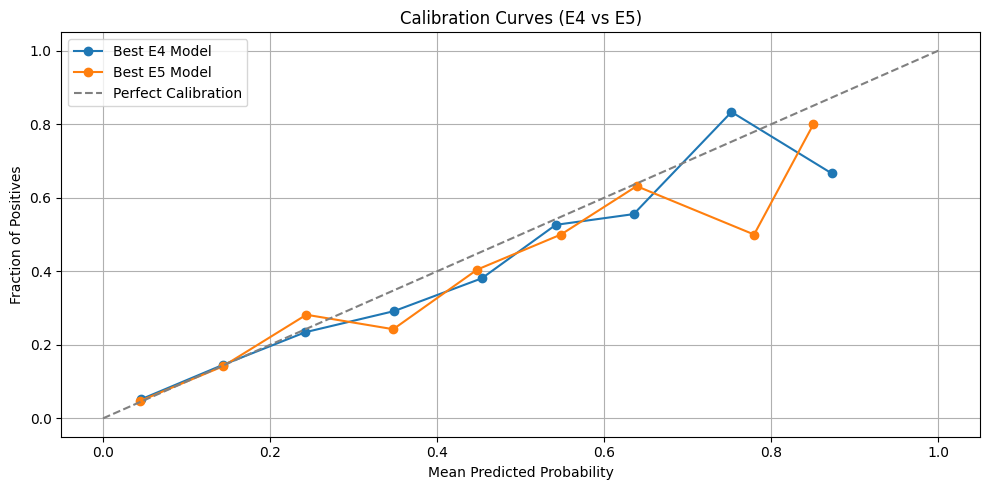


Selected Champion Model: E5_Logistic Regression


['champion_diabetes_model.joblib']

In [29]:
# Experiment 6: Statistical Comparison & Champion Selection
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve

# 1. Select the best performing models from E4 and E5 based on test ROC-AUC
best_e4_name = df_e4_results['Test ROC-AUC'].idxmax()
best_e4_model = best_estimators_e4[best_e4_name]
best_e5_name = df_e5_results['Test ROC-AUC'].idxmax()
best_e5_model = best_estimators_e5[best_e5_name]

print(f"Best E4 Model: {best_e4_name} (Test AUC: {df_e4_results.loc[best_e4_name, 'Test ROC-AUC']:.4f})")
print(f"Best E5 Model: {best_e5_name} (Test AUC: {df_e5_results.loc[best_e5_name, 'Test ROC-AUC']:.4f})")

# Get predictions
y_prob_e4 = best_e4_model.predict_proba(X_test_e4)[:, 1]
y_prob_e5 = best_e5_model.predict_proba(X_test_e5)[:, 1]

# 2. Bootstrapping to compare E4 vs E5 ROC-AUC
n_bootstraps = 1000
boot_auc_diffs = []
np.random.seed(42)

for i in range(n_bootstraps):
    indices = np.random.choice(len(y_test), size=len(y_test), replace=True)
    if len(np.unique(y_test.iloc[indices])) < 2:
        continue
    auc_e4 = roc_auc_score(y_test.iloc[indices], y_prob_e4[indices])
    auc_e5 = roc_auc_score(y_test.iloc[indices], y_prob_e5[indices])
    boot_auc_diffs.append(auc_e5 - auc_e4)

boot_auc_diffs = np.array(boot_auc_diffs)
p_value = np.mean(boot_auc_diffs <= 0)
ci_lower = np.percentile(boot_auc_diffs, 2.5)
ci_upper = np.percentile(boot_auc_diffs, 97.5)

print(f"\n=== Bootstrapping Results (E5 AUC - E4 AUC) ===")
print(f"Mean Difference: {np.mean(boot_auc_diffs):.4f}")
print(f"95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"Empirical p-value (E5 <= E4): {p_value:.4f}")

# 3. Plot Calibration Curves
plt.figure(figsize=(10, 5))
for name, probs in [('Best E4 Model', y_prob_e4), ('Best E5 Model', y_prob_e5)]:
    prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=10, strategy='uniform')
    plt.plot(prob_pred, prob_true, marker='o', label=name)

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curves (E4 vs E5)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('calibration_comparison.png')
plt.show()

# Select overall champion
champion_model = best_e5_model if df_e5_results.loc[best_e5_name, 'Test ROC-AUC'] >= df_e4_results.loc[best_e4_name, 'Test ROC-AUC'] else best_e4_model
champion_name = f"E5_{best_e5_name}" if champion_model == best_e5_model else f"E4_{best_e4_name}"
print(f"\nSelected Champion Model: {champion_name}")
joblib.dump(champion_model, 'champion_diabetes_model.joblib')


/tmp/ipykernel_1868/2613292749.py:18: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_e5_trans, show=False)


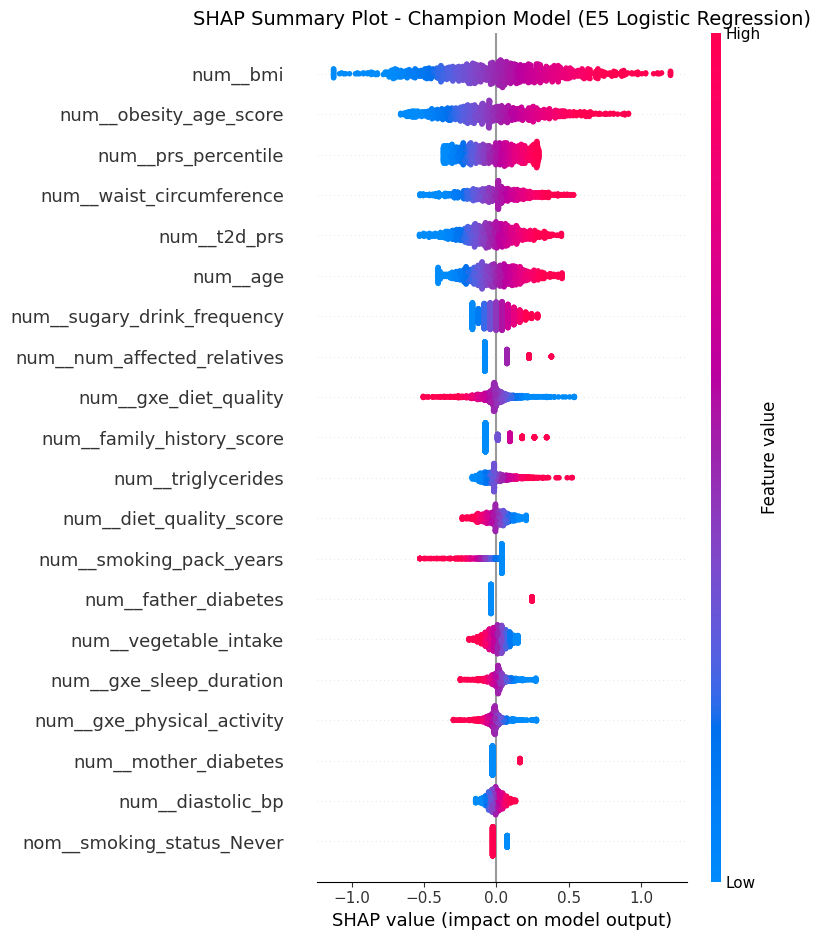


=== Subgroup Analysis Performance ===

Performance by Sex:
  * Female          | Count: 547  | ROC-AUC: 0.7529 | PR-AUC: 0.3967
  * Male            | Count: 503  | ROC-AUC: 0.8257 | PR-AUC: 0.4403

Performance by Age Band:
  * <30             | Count: 127  | ROC-AUC: 0.8230 | PR-AUC: 0.3475
  * 30-45           | Count: 361  | ROC-AUC: 0.7339 | PR-AUC: 0.2082
  * 46-60           | Count: 396  | ROC-AUC: 0.7411 | PR-AUC: 0.3989
  * 60+             | Count: 166  | ROC-AUC: 0.7770 | PR-AUC: 0.5773

Performance by Genetic Risk Category:
  * High            | Count: 250  | ROC-AUC: 0.7701 | PR-AUC: 0.5171
  * Low             | Count: 265  | ROC-AUC: 0.7769 | PR-AUC: 0.3586
  * Medium          | Count: 535  | ROC-AUC: 0.7510 | PR-AUC: 0.3567


In [30]:
# 1. Interpretability: SHAP Analysis for Champion Model (Logistic Regression)
import shap

# Preprocess the test set to obtain standard feature names
X_test_e5_trans = preprocessor_e5.transform(X_test_e5)

# Fit SHAP Explainer (Linear Explainer for Logistic Regression champion)
# Extract underlying classifier step from pipeline
clf = champion_model.named_steps['classifier']

# Use background summary data for SHAP computation
X_train_e5_trans = preprocessor_e5.transform(X_train_e5)
explainer = shap.LinearExplainer(clf, X_train_e5_trans)
shap_values = explainer(X_test_e5_trans)

# Plot and save SHAP summary plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_e5_trans, show=False)
plt.title("SHAP Summary Plot - Champion Model (E5 Logistic Regression)", fontsize=14)
plt.tight_layout()
plt.savefig("champion_shap_summary.png")
plt.show()

# 2. Subgroup Performance Analysis
# Re-attach target and demographic grouping features
subgroup_df = X_test.copy()
subgroup_df['target'] = y_test
subgroup_df['pred_prob'] = champion_model.predict_proba(X_test_e5)[:, 1]

# Create Age bands
subgroup_df['age_band'] = pd.cut(subgroup_df['age'], bins=[0, 30, 45, 60, 100], labels=['<30', '30-45', '46-60', '60+'])

subgroups = {
    'Sex': 'sex',
    'Age Band': 'age_band',
    'Genetic Risk Category': 'genetic_risk_category'
}

print("\n=== Subgroup Analysis Performance ===")
for title, col in subgroups.items():
    print(f"\nPerformance by {title}:")
    for category, grp in subgroup_df.groupby(col, observed=True):
        if len(grp['target'].unique()) >= 2:
            auc = roc_auc_score(grp['target'], grp['pred_prob'])
            ap = average_precision_score(grp['target'], grp['pred_prob'])
            print(f"  * {category:<15} | Count: {len(grp):<4} | ROC-AUC: {auc:.4f} | PR-AUC: {ap:.4f}")
        else:
            print(f"  * {category:<15} | Count: {len(grp):<4} | ROC-AUC: N/A (single-class subgroup)")
